In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df_train = pd.read_csv("train.csv")

df_test = pd.read_csv("test.csv")

## Checking the missingness of features

In [19]:
missing_percent = (df_train.isna().mean() * 100).sort_values(ascending=False)

print(missing_percent.round(2).to_string())

scl_avg                             95.98
badgeType                           91.79
spo2                                69.04
activityType                        55.26
exertion_points_percentage          54.44
responsiveness_points_percentage    54.44
stress_score                        54.44
sleep_points_percentage             54.44
rmssd                               49.31
nremhr                              49.31
full_sleep_breathing_rate           48.76
sleep_wake_ratio                    28.10
sleep_rem_ratio                     28.10
sleep_deep_ratio                    28.10
sleep_light_ratio                   28.10
daily_temperature_variation         26.83
nightly_temperature                 25.90
min_goal                            24.63
max_goal                            24.63
step_goal                           24.63
step_goal_label                     24.52
minutesAwake                        23.42
minutesAfterWakeup                  23.42
sleep_efficiency                  

Some features with high missing value cannot be used for our classification task

## Check Stats of some candidate features

In [4]:


candidate_features = [
    "age", "bmi",
    "steps", "calories",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "bpm", "resting_hr", "rmssd",
    "sleep_duration", "sleep_efficiency",
    "stress_score"
]


eda = df_train[candidate_features].copy()


for col in candidate_features:
    eda[col] = pd.to_numeric(eda[col], errors="coerce")


summary = eda.describe().T

summary["missing_percent"] = (
    eda.isna().mean() * 100
)

print(summary.round(2).to_string())


print("\nGENDER DISTRIBUTION")
print(df_train["gender"].value_counts(dropna=False))

# Check whether age and BMI contain nonnumeric values
for col in ["age", "bmi"]:
    invalid = (
        df_train[col].notna()
        & pd.to_numeric(
            df_train[col], errors="coerce"
        ).isna()
    )

    print(f"\nNonnumeric {col} values:")
    print(df_train.loc[invalid, col].value_counts())


                            count         mean         std         min          25%          50%          75%          max  missing_percent
age                           0.0          NaN         NaN         NaN          NaN          NaN          NaN          NaN           100.00
bmi                        1391.0        22.57        2.31       19.00        20.00        22.00        24.00        29.00            23.36
steps                      1652.0      8760.89     5342.59        0.00      5111.50      7905.50     11466.75     32577.00             8.98
calories                   1773.0      2465.59      721.20      996.97      1982.09      2351.59      2829.96      8387.03             2.31
lightly_active_minutes     1773.0       196.84      105.90        0.00       128.00       202.00       271.00       585.00             2.31
moderately_active_minutes  1773.0        21.96       29.14        0.00         0.00        13.00        31.00       289.00             2.31
very_active_minutes 

-> Age is categorical here.
-> BMI some values categorical and others numerical

## Histogram of some Candidate features

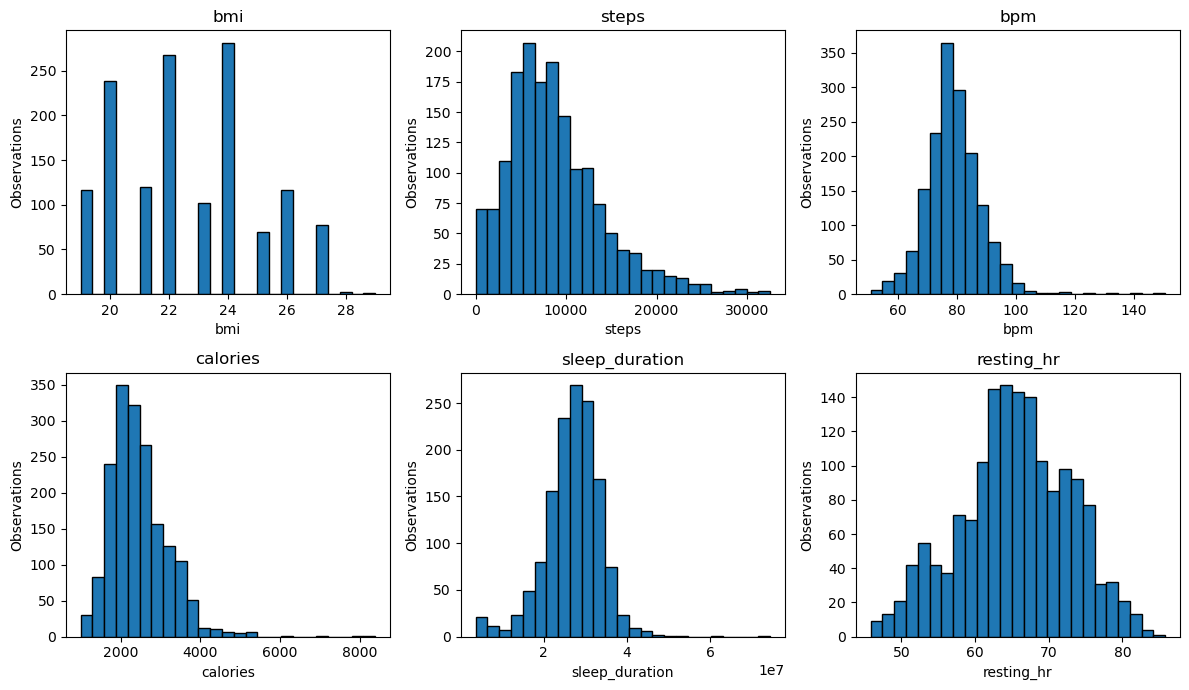

In [8]:


plot_features = [
    "bmi",
    "steps",
    "bpm",
    "calories",
    "sleep_duration",
    "resting_hr"
    
    
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, feature in zip(axes.flat, plot_features):

    values = eda[feature].dropna()

    ax.hist(values, bins=25, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Observations")

plt.tight_layout()
plt.show()

## Age category plot and corected sleep_duration

AGE DISTRIBUTION
age
>=30    954
<30     798
NaN      63
Name: count, dtype: int64

BMI DISTRIBUTION
bmi
19.0    117
20.0    238
21.0    120
22.0    267
23.0    102
24.0    281
25.0     69
26.0    117
27.0     77
28.0      2
29.0      1
<19     103
>=25    153
>=30    105
NaN      63
Name: count, dtype: int64

SLEEP DURATION IN HOURS
count    1390.000000
mean        7.502854
std         1.894908
min         1.000000
25%         6.516667
50%         7.650000
75%         8.650000
max        20.683333
Name: sleep_hours, dtype: float64

Sleep duration <= 2 hours:
25

Sleep duration > 12 hours:
12


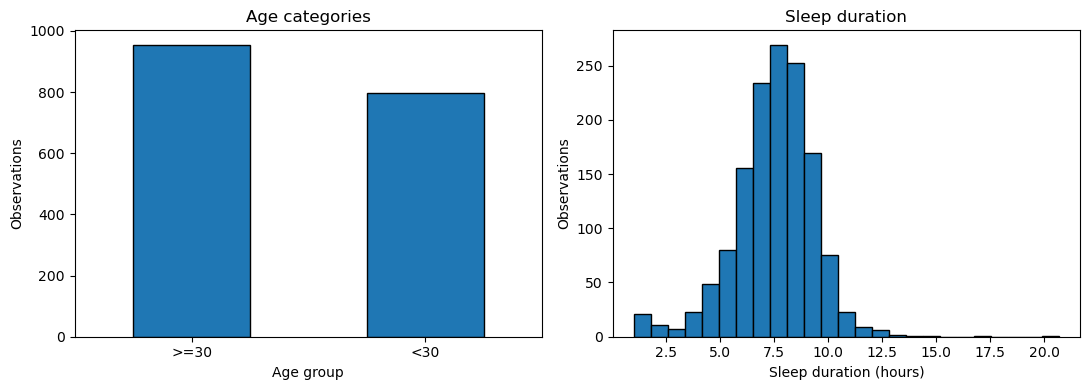

In [9]:
eda_clean = df_train.copy()

# Age: 
print("AGE DISTRIBUTION")
print(eda_clean["age"].value_counts(dropna=False))

# BMI: 
print("\nBMI DISTRIBUTION")
print(
    eda_clean["bmi"]
    .value_counts(dropna=False)
    .sort_index()
)

# Convert sleep duration from milliseconds to hours
eda_clean["sleep_hours"] = (
    pd.to_numeric(
        eda_clean["sleep_duration"],
        errors="coerce"
    ) / 3_600_000
)

print("\nSLEEP DURATION IN HOURS")
print(eda_clean["sleep_hours"].describe())

# Check extremely short and long sleep durations
print("\nSleep duration <= 2 hours:")
print((eda_clean["sleep_hours"] <= 2).sum())

print("\nSleep duration > 12 hours:")
print((eda_clean["sleep_hours"] > 12).sum())

# Age and corrected sleep plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

eda_clean["age"].value_counts().plot(
    kind="bar",
    ax=axes[0],
    edgecolor="black"
)
axes[0].set_title("Age categories")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("Observations")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(
    eda_clean["sleep_hours"].dropna(),
    bins=25,
    edgecolor="black"
)
axes[1].set_title("Sleep duration")
axes[1].set_xlabel("Sleep duration (hours)")
axes[1].set_ylabel("Observations")

plt.tight_layout()
plt.show()

## Close look at BMI which appears to be both numeric and categorical

In [11]:
# PART A: BMI representation across participants

# How many distinct BMI values does each participant have?
bmi_per_participant = (
    df_train.groupby("id")["bmi"]
    .nunique(dropna=True)
)




print("DISTINCT BMI VALUES PER PARTICIPANT")
print(bmi_per_participant.value_counts().sort_index())

# Identify whether BMI is numeric-looking or a range category
bmi_numeric = pd.to_numeric(
    df_train["bmi"], errors="coerce"       # converts non-numeric to NAN
)

bmi_type = pd.Series("numeric", index=df_train.index)
bmi_type[df_train["bmi"].isna()] = "missing"

bmi_type[
    df_train["bmi"].notna() & bmi_numeric.isna()
] = "category"

bmi_check = df_train[["id", "bmi"]].copy()
bmi_check["bmi_type"] = bmi_type

print("\nBMI REPRESENTATION")
print(bmi_check["bmi_type"].value_counts())

# Does any participant have both exact numeric and category values?
types_per_participant = (
    bmi_check[bmi_check["bmi_type"] != "missing"]
    .groupby("id")["bmi_type"]
    .nunique()
)

print("\nParticipants with both BMI representations:")
print((types_per_participant > 1).sum())


DISTINCT BMI VALUES PER PARTICIPANT
bmi
0     3
1    60
Name: count, dtype: int64

BMI REPRESENTATION
bmi_type
numeric     1391
category     361
missing       63
Name: count, dtype: int64

Participants with both BMI representations:
0


## Plots to see whether candidate features affect the next day happiness/ tired?

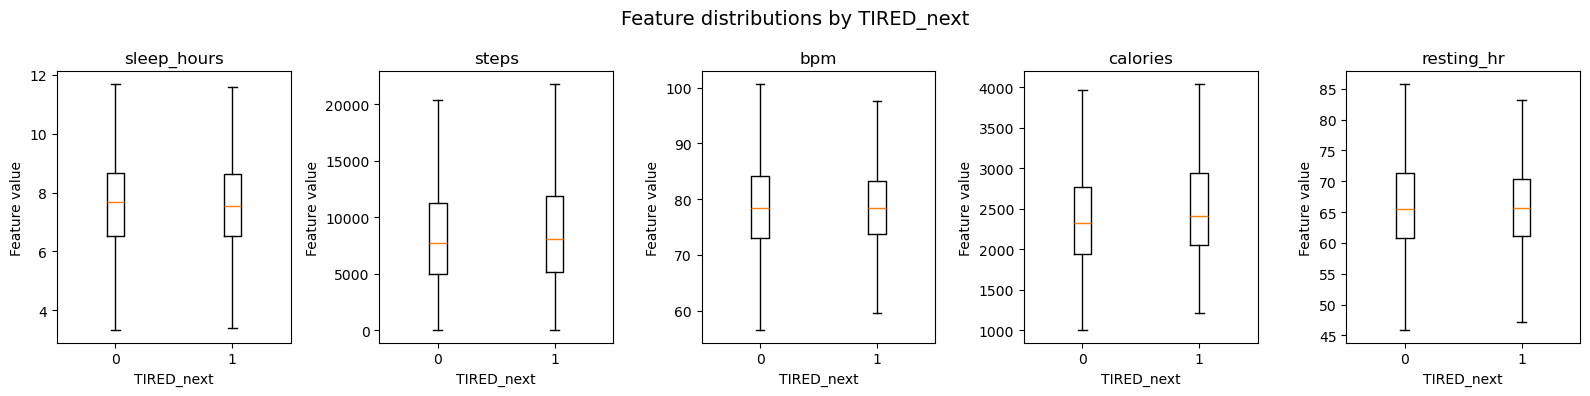

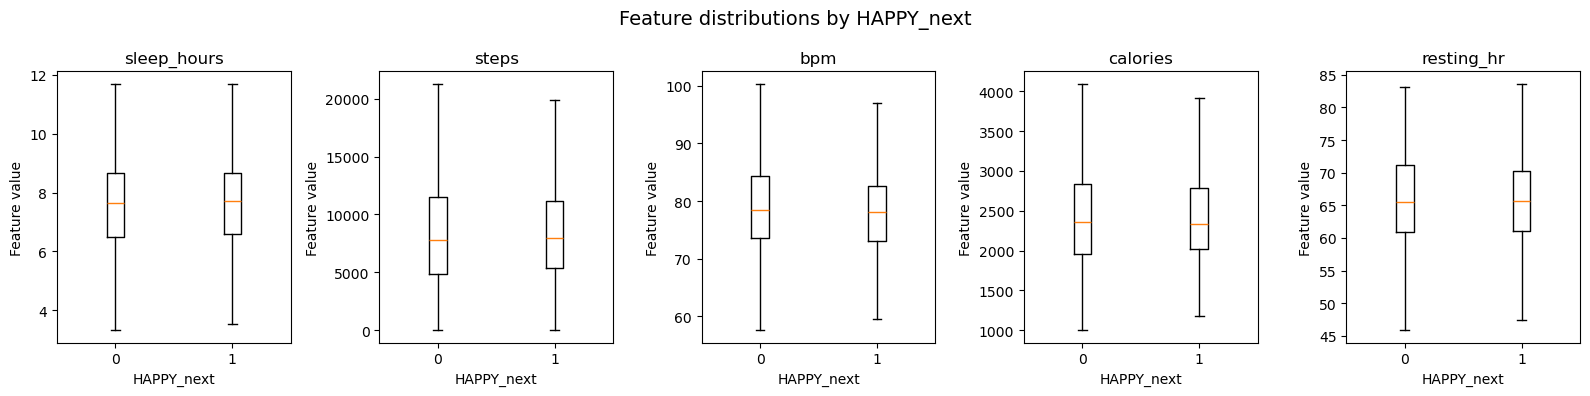

In [9]:



eda = df_train.copy()


eda["sleep_hours"] = (
    pd.to_numeric(eda["sleep_duration"], errors="coerce")
    / 3_600_000
)

features = [
    "sleep_hours",
    "steps",
    "bpm",
    "calories",
    "resting_hr"
]

targets = ["TIRED_next", "HAPPY_next"]

for target in targets:

    fig, axes = plt.subplots(
        1, len(features),
        figsize=(16, 4)
    )

    for ax, feature in zip(axes, features):

        # Compare feature values for target = 0 and target = 1
        group0 = eda.loc[
            eda[target] == 0, feature
        ].dropna()

        group1 = eda.loc[
            eda[target] == 1, feature
        ].dropna()

        ax.boxplot(
            [group0, group1],
            tick_labels=["0", "1"],
            showfliers=False
        )

        ax.set_title(feature)
        ax.set_xlabel(target)
        ax.set_ylabel("Feature value")

    fig.suptitle(
        f"Feature distributions by {target}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

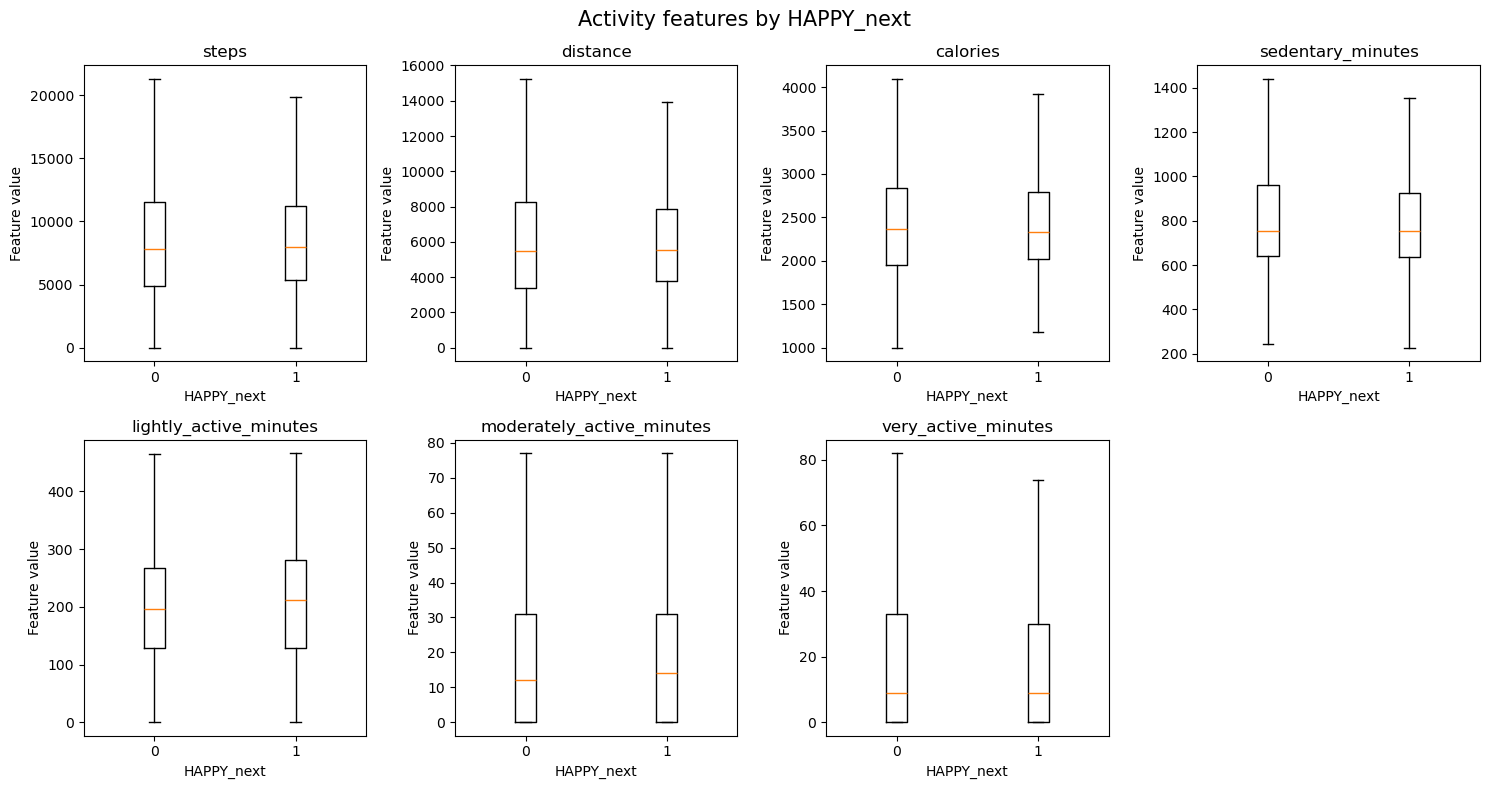

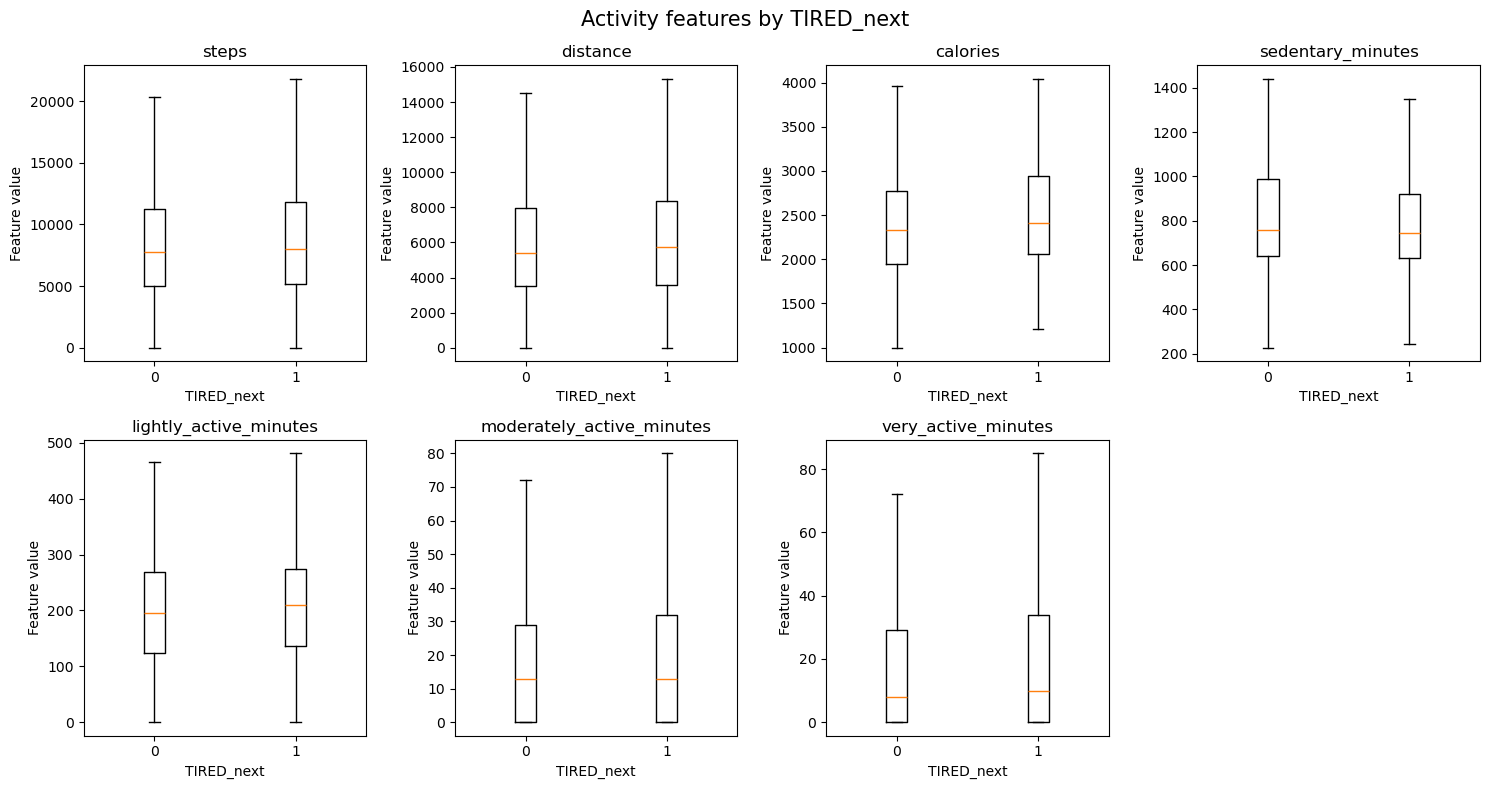

In [13]:



eda = df_train.copy()

activity_features = [
    "steps",
    "distance",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes"
]

targets = ["HAPPY_next", "TIRED_next"]

for target in targets:

    fig, axes = plt.subplots(
        2, 4, figsize=(15, 8)
    )

    for ax, feature in zip(axes.flat, activity_features):

        values0 = pd.to_numeric(
            eda.loc[eda[target] == 0, feature],
            errors="coerce"
        ).dropna()

        values1 = pd.to_numeric(
            eda.loc[eda[target] == 1, feature],
            errors="coerce"
        ).dropna()

        ax.boxplot(
            [values0, values1],
            tick_labels=["0", "1"],
            showfliers=False
        )

        ax.set_title(feature)
        ax.set_xlabel(target)
        ax.set_ylabel("Feature value")


    axes.flat[-1].axis("off")

    fig.suptitle(
        f"Activity features by {target}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


In [12]:

for target in ["HAPPY_next", "TIRED_next"]:

    print(f"\n========== {target} ==========")

    results = (
        eda.groupby(target)[activity_features]
        .agg(["count", "median"])
    )

    print(results.T)


========== HAPPY_next ==========
HAPPY_next                            0.0       1.0
steps                     count   1165.00   487.000
                          median  7833.00  7971.000
distance                  count   1165.00   487.000
                          median  5474.80  5567.600
calories                  count   1253.00   520.000
                          median  2360.31  2332.555
sedentary_minutes         count   1253.00   520.000
                          median   753.00   752.500
lightly_active_minutes    count   1253.00   520.000
                          median   196.00   212.000
moderately_active_minutes count   1253.00   520.000
                          median    12.00    14.000
very_active_minutes       count   1253.00   520.000
                          median     9.00     9.000

========== TIRED_next ==========
TIRED_next                            0.0      1.0
steps                     count   1004.00   648.00
                          median  7726.50  8033.00

There is some noticeable differences here...

-> A person is likely to be happy/tired when they have taken more steps  and in general did more activities. Hence , these might be usefull features when we classify between happy or tired people

## Correlation between activity features

ACTIVITY FEATURE CORRELATIONS
                           steps  distance  calories  sedentary_minutes  \
steps                       1.00      0.98      0.64              -0.46   
distance                    0.98      1.00      0.65              -0.45   
calories                    0.64      0.65      1.00              -0.35   
sedentary_minutes          -0.46     -0.45     -0.35               1.00   
lightly_active_minutes      0.61      0.60      0.41              -0.62   
moderately_active_minutes   0.73      0.72      0.64              -0.44   
very_active_minutes         0.73      0.72      0.67              -0.36   

                           lightly_active_minutes  moderately_active_minutes  \
steps                                        0.61                       0.73   
distance                                     0.60                       0.72   
calories                                     0.41                       0.64   
sedentary_minutes                           -0.62

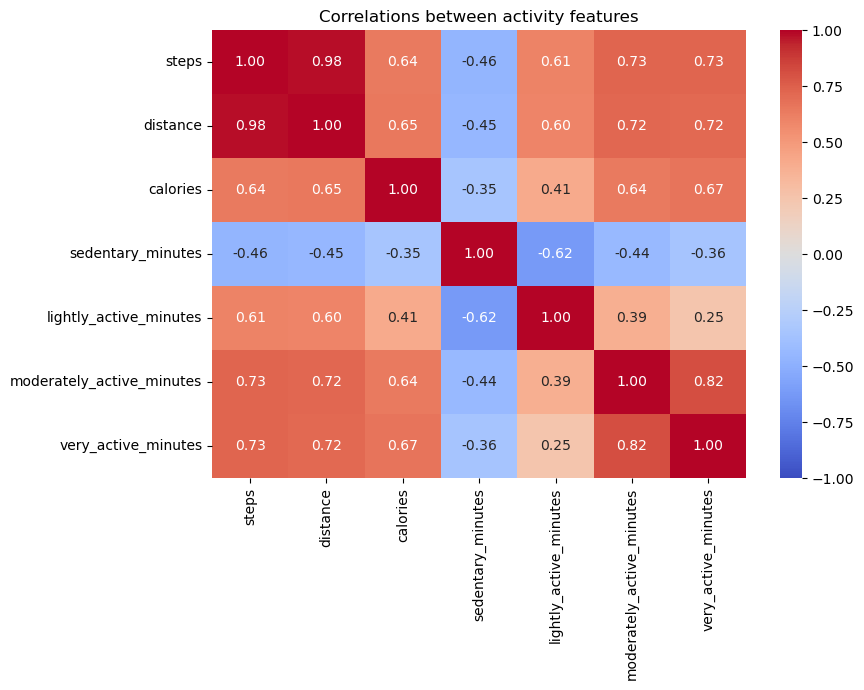

In [14]:
import seaborn as sns

activity_features = [
    "steps",
    "distance",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes"
]


activity_data = df_train[activity_features].copy()

# Spearman correlation
corr = activity_data.corr(method="spearman")

print("ACTIVITY FEATURE CORRELATIONS")
print(corr.round(2))

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlations between activity features")
plt.tight_layout()
plt.show()

High correlation between steps and distance . I think one can remove distance as one of the feature

## Correlation between Sleep features

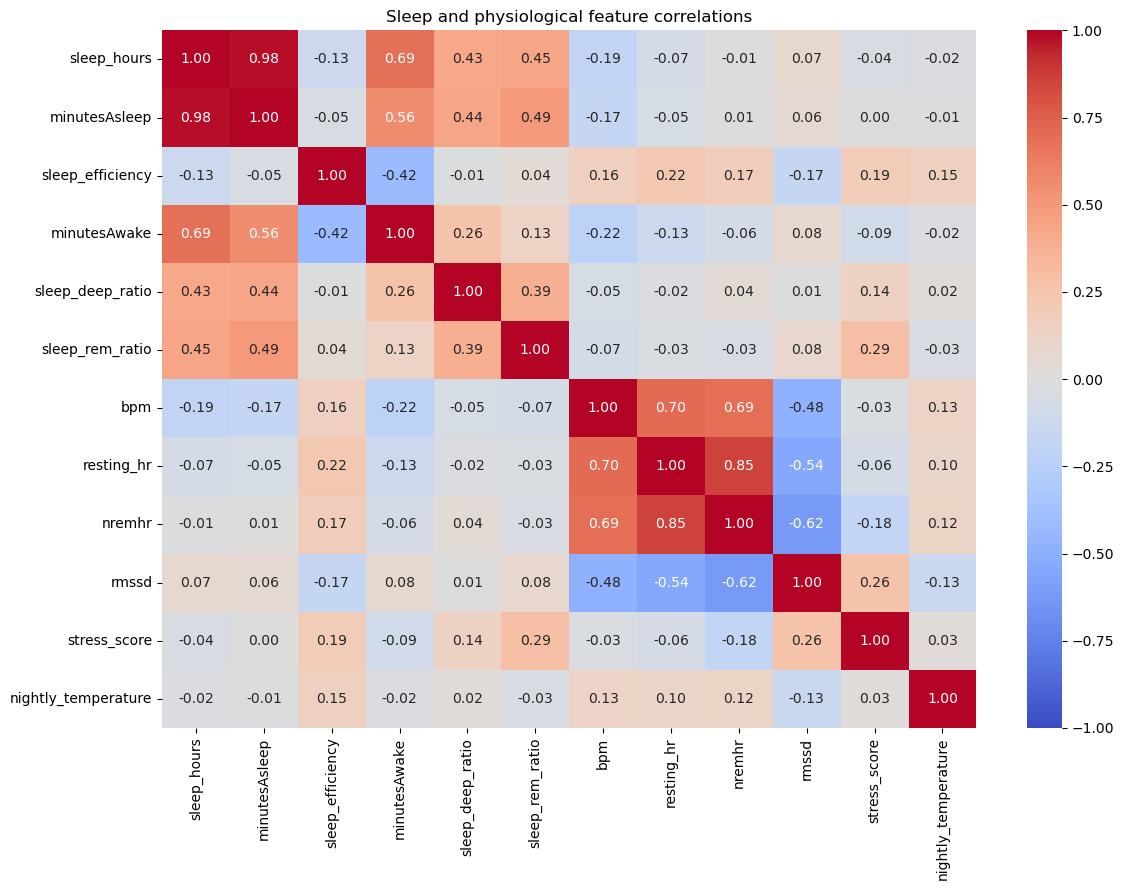

In [15]:



eda = df_train.copy()

# Convert sleep to   hours
eda["sleep_hours"] = (
    pd.to_numeric(
        eda["sleep_duration"], errors="coerce"
    ) / 3_600_000
)

physio_features = [
    "sleep_hours",
    "minutesAsleep",
    "sleep_efficiency",
    "minutesAwake",
    "sleep_deep_ratio",
    "sleep_rem_ratio",
    "bpm",
    "resting_hr",
    "nremhr",
    "rmssd",
    "stress_score",
    "nightly_temperature"
]



# Spearman correlations
corr = eda[physio_features].corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Sleep and physiological feature correlations")
plt.tight_layout()
plt.show()


Shows MinutesAsleep and Sleep_hours highly correlated , so we can remove either of these

## Next day mood by age and gender

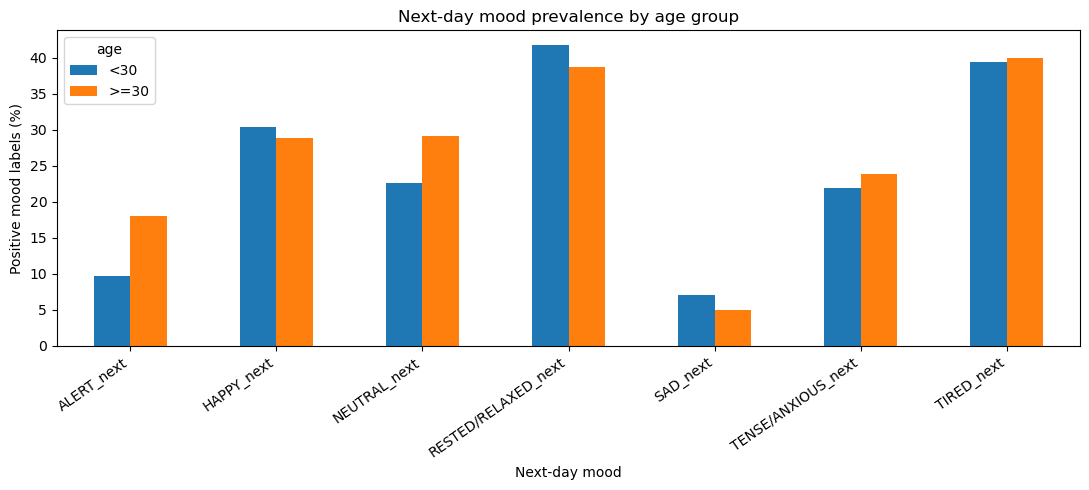

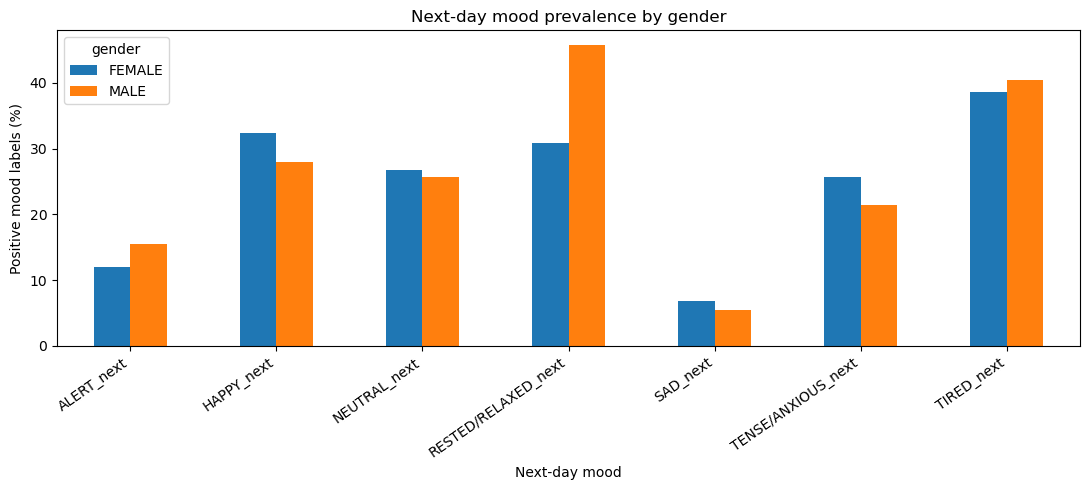

In [17]:



mood_list = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]

next_cols = [f"{m}_next" for m in mood_list]


eda = df_train.copy()

# Mood prevalence by age
age_mood = (
    eda.groupby("age")[next_cols]
    .mean() * 100
)

# Mood prevalence by gender
gender_mood = (
    eda.groupby("gender")[next_cols]
    .mean() * 100
)
'''
print("MOOD PREVALENCE BY AGE (%)")
print(age_mood.round(2))

print("\nMOOD PREVALENCE BY GENDER (%)")
print(gender_mood.round(2))'''

# Plot age comparison
ax = age_mood.T.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_ylabel("Positive mood labels (%)")
ax.set_xlabel("Next-day mood")
ax.set_title("Next-day mood prevalence by age group")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Plot gender comparison
ax = gender_mood.T.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_ylabel("Positive mood labels (%)")
ax.set_xlabel("Next-day mood")
ax.set_title("Next-day mood prevalence by gender")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


That's approximately a 15-percentage-point difference between males and females on rested_next.

People with age 30 or above is highly alert compared to less than 30 age people

Age group might contain information about next-day ALERT.



Age group might add relatively little information about next-day TIRED when considered alone.

## Next Day mood by BMI

BMI GROUP DISTRIBUTION
bmi_group
19–<25    1125
>=25       524
<19        103
NaN         63
Name: count, dtype: int64

MOOD PREVALENCE BY BMI GROUP (%)
           ALERT_next  HAPPY_next  NEUTRAL_next  RESTED/RELAXED_next  \
bmi_group                                                              
19–<25          15.64       28.80         23.91                45.78   
<19              5.83       33.98         28.16                24.27   
>=25            12.79       30.53         30.53                30.92   

           SAD_next  TENSE/ANXIOUS_next  TIRED_next  
bmi_group                                            
19–<25         4.98               25.24       35.64  
<19            3.88               23.30       27.18  
>=25           8.40               18.13       50.95  


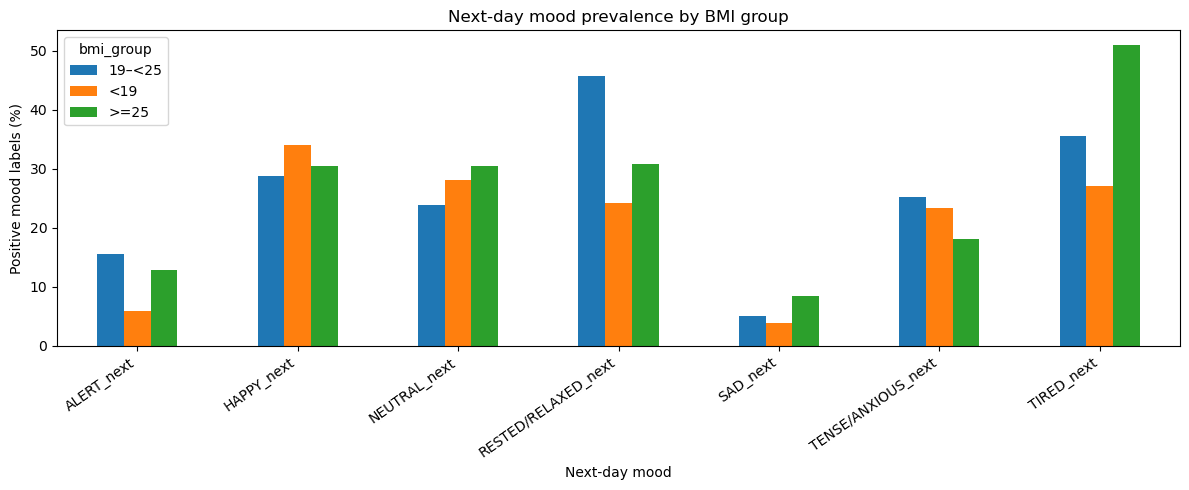

In [19]:


eda = df_train.copy()

def bmi_group(value):   # making 3 categories for BMI

    if pd.isna(value):
        return np.nan

    if value == "<19":
        return "<19"

    if value in [">=25", ">=30"]:
        return ">=25"

    value = float(value)

    if value < 19:
        return "<19"
    elif value < 25:
        return "19–<25"
    else:
        return ">=25"

eda["bmi_group"] = eda["bmi"].apply(bmi_group)


print("BMI GROUP DISTRIBUTION")
print(eda["bmi_group"].value_counts(dropna=False))


# Calculate positive mood percentages
bmi_mood = (
    eda.groupby("bmi_group")[next_cols]
    .mean() * 100
)

print("\nMOOD PREVALENCE BY BMI GROUP (%)")
print(bmi_mood.round(2))


ax = bmi_mood.T.plot(
    kind="bar",
    figsize=(12, 5)
)

ax.set_xlabel("Next-day mood")
ax.set_ylabel("Positive mood labels (%)")
ax.set_title("Next-day mood prevalence by BMI group")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [20]:


print("OBSERVATIONS PER BMI GROUP")
print(
    eda.groupby("bmi_group", dropna=False)
    .size()
)


print("\nUNIQUE PARTICIPANTS PER BMI GROUP")
print(
    eda.groupby("bmi_group", dropna=False)["id"]
    .nunique()
)


OBSERVATIONS PER BMI GROUP
bmi_group
19–<25    1125
<19        103
>=25       524
NaN         63
dtype: int64

UNIQUE PARTICIPANTS PER BMI GROUP
bmi_group
19–<25    36
<19        6
>=25      18
NaN        6
Name: id, dtype: int64


## Check on Contextual variables

In [24]:

context_cols = [
    "ENTERTAINMENT",
    "GYM",
    "HOME",
    "HOME_OFFICE",
    "OTHER",
    "OUTDOORS",
    "TRANSIT",
    "WORK/SCHOOL"
]


context_data = df_train[context_cols].copy()


for col in context_cols:
    print(f"\n{col}")
    print(context_data[col].value_counts(dropna=False))

# Number of observations with context information
print("\nOBSERVATIONS WITH CONTEXT INFORMATION")
print(context_data.notna().all(axis=1).sum())

# Check whether context is available when
# today's mood labels are missing
mood_cols = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]

has_context = context_data.notna().all(axis=1)
has_today_mood = df_train[mood_cols].notna().all(axis=1)

print("\nCONTEXT AVAILABILITY VS TODAY'S MOOD")
print(pd.crosstab(
    has_today_mood,
    has_context,
    rownames=["Today's mood recorded"],
    colnames=["Context available"]
))



ENTERTAINMENT
ENTERTAINMENT
0.0    1464
NaN     202
1.0     149
Name: count, dtype: int64

GYM
GYM
0.0    1599
NaN     202
1.0      14
Name: count, dtype: int64

HOME
HOME
1.0    1285
0.0     328
NaN     202
Name: count, dtype: int64

HOME_OFFICE
HOME_OFFICE
0.0    1461
NaN     202
1.0     152
Name: count, dtype: int64

OTHER
OTHER
0.0    1569
NaN     202
1.0      44
Name: count, dtype: int64

OUTDOORS
OUTDOORS
0.0    1356
1.0     257
NaN     202
Name: count, dtype: int64

TRANSIT
TRANSIT
0.0    1462
NaN     202
1.0     151
Name: count, dtype: int64

WORK/SCHOOL
WORK/SCHOOL
0.0    1150
1.0     463
NaN     202
Name: count, dtype: int64

OBSERVATIONS WITH CONTEXT INFORMATION
1613

CONTEXT AVAILABILITY VS TODAY'S MOOD
Context available      False  True 
Today's mood recorded              
False                    202      0
True                       0   1613


Whenever today's seven mood labels are recorded, all eight contextual variables are also recorded. Whenever today's mood labels are missing, all eight contextual variables are missing.
This strongly suggests that these variables were collected together, perhaps through the same daily questionnaire. We would need the dataset documentation to confirm that.
This is different from wearable measurements, which can be recorded even when participants don't complete a mood report.

In [26]:

context_cols = [
    "ENTERTAINMENT", "GYM", "HOME",
    "HOME_OFFICE", "OTHER", "OUTDOORS",
    "TRANSIT", "WORK/SCHOOL"
]


context_labeled = df_train.dropna(
    subset=context_cols
).copy()

# Count how many contexts are marked as 1 in each row
context_labeled["n_contexts"] = (
    context_labeled[context_cols] == 1
).sum(axis=1)

print("NUMBER OF CONTEXTS RECORDED PER OBSERVATION")
print(
    context_labeled["n_contexts"]
    .value_counts()
    .sort_index()
)


NUMBER OF CONTEXTS RECORDED PER OBSERVATION
n_contexts
1    821
2    682
3    110
Name: count, dtype: int64


This confirms that context is multi-label, just like your mood variables.

## Feature correlation with next day moods

FEATURE-MOOD CORRELATIONS
                           ALERT_next  HAPPY_next  NEUTRAL_next  \
steps                          -0.046       0.020         0.069   
distance                       -0.042       0.021         0.064   
calories                        0.049       0.004         0.031   
sedentary_minutes              -0.000      -0.016        -0.076   
lightly_active_minutes          0.015       0.039         0.110   
moderately_active_minutes      -0.020       0.030         0.055   
very_active_minutes            -0.047      -0.013         0.032   
sleep_hours                    -0.098       0.006        -0.056   
sleep_efficiency                0.060       0.052        -0.004   
minutesAwake                   -0.070      -0.042        -0.056   
sleep_deep_ratio                0.011       0.036         0.003   
sleep_rem_ratio                -0.010       0.059        -0.027   
bpm                             0.028      -0.040        -0.026   
resting_hr                      0.09

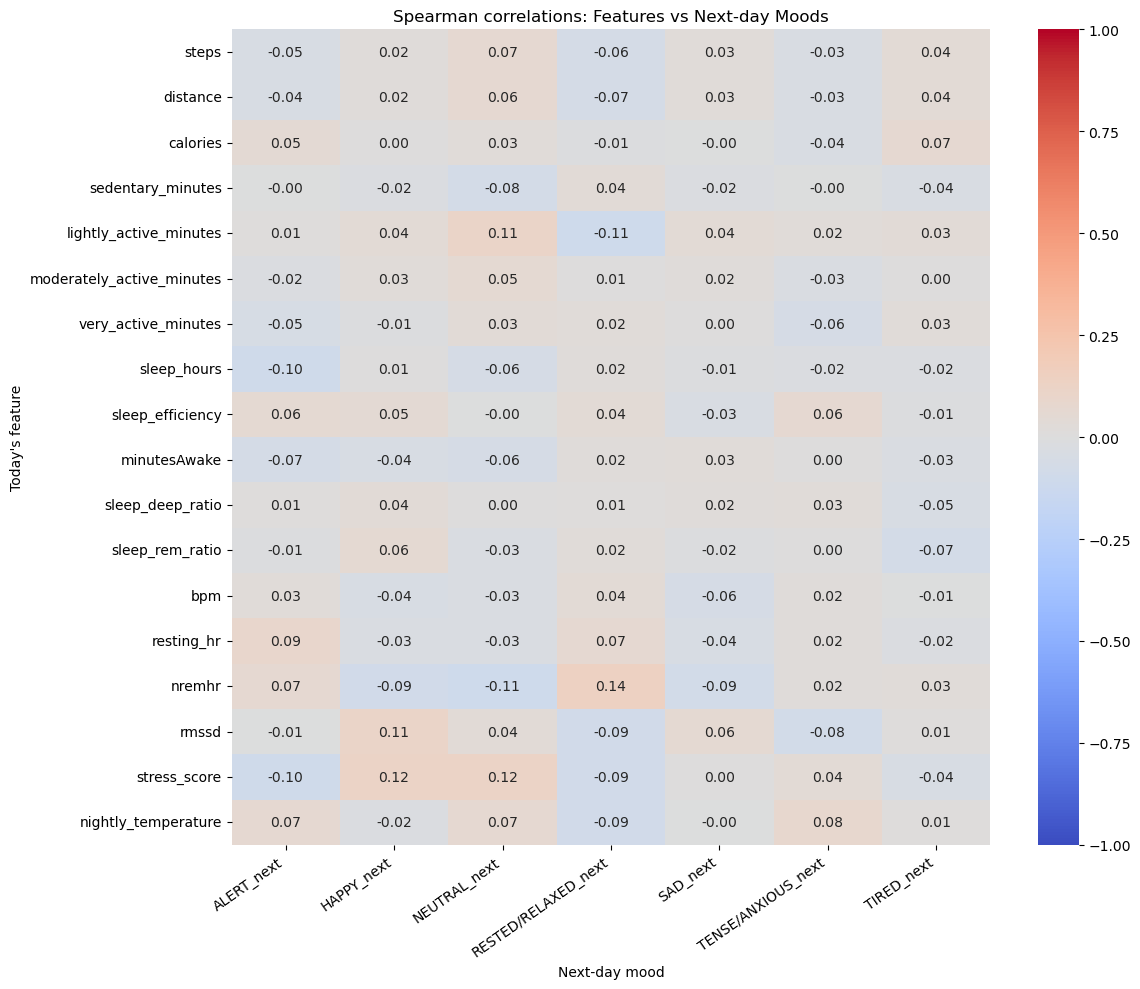

In [21]:


# Training data only
eda = df_train.copy()

eda["sleep_hours"] = (
    pd.to_numeric(eda["sleep_duration"], errors="coerce")
    / 3_600_000
)

numeric_features = [
    "steps",
    "distance",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "sleep_hours",
    "sleep_efficiency",
    "minutesAwake",
    "sleep_deep_ratio",
    "sleep_rem_ratio",
    "bpm",
    "resting_hr",
    "nremhr",
    "rmssd",
    "stress_score",
    "nightly_temperature"
]

next_cols = [
    "ALERT_next",
    "HAPPY_next",
    "NEUTRAL_next",
    "RESTED/RELAXED_next",
    "SAD_next",
    "TENSE/ANXIOUS_next",
    "TIRED_next"
]


for col in numeric_features:
    eda[col] = pd.to_numeric(eda[col], errors="coerce")


corr = eda[numeric_features + next_cols].corr(
    method="spearman"
)


feature_mood_corr = corr.loc[
    numeric_features, next_cols
]

print("FEATURE-MOOD CORRELATIONS")
print(feature_mood_corr.round(3))


plt.figure(figsize=(12, 10))

sns.heatmap(
    feature_mood_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.xlabel("Next-day mood")
plt.ylabel("Today's feature")
plt.title("Spearman correlations: Features vs Next-day Moods")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


Most of the numerical features show very weak individual correlations with tomorrow's mood labels.
That doesn't mean our prediction project won't work. It means we need to think carefully about what information a model can learn beyond simple one-feature relationships.



A feature may be useful in combination with others, even when its individual correlation is close to zero.